# Reminder:

Notebook consists of code and small descriptions. Check report.pdf for a detailed German presentation. And the additional assignment "Weitere Fragen"

In [1]:
# imports and helper function
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, auc, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

def plot_roc_curve(y_true, y_proba, title='ROC Curve'):

    fpr, tpr, _ = roc_curve(
        y_true,
        y_proba,
        pos_label=1
    )

    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})')

    plt.plot([0, 1], [0, 1], linestyle='--', color='gray',label='Random Classifier')

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate (Recall)')
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

    return roc_auc


## Marketing Campaign 

-> Goal: Acquire customers for term deposits

-> Predict Y


Interpretation: Find a good trade off between Recall and Precison -> acquire as many possible customers while keeping the cost of reaching out to people as low as possible

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
bank_marketing = fetch_ucirepo(id=222) 
  
# data (as pandas dataframes) 
X = bank_marketing.data.features 
y = bank_marketing.data.targets 


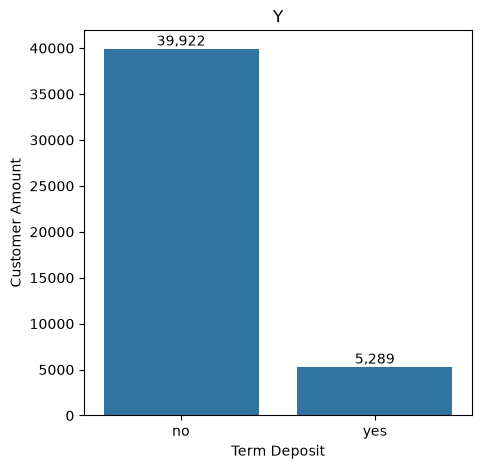

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [3]:
# target distribution
target_counts = y.squeeze().value_counts()

plt.figure(figsize=(5, 5))
sns.barplot(
    x=target_counts.index,
    y=target_counts.values
)

plt.title("Y")
plt.xlabel("Term Deposit")
plt.ylabel("Customer Amount")

for i, value in enumerate(target_counts.values):
    plt.text(i, value, f"{value:,}", ha="center", va="bottom")

plt.show()
print(y.squeeze().value_counts(normalize=True) * 100)

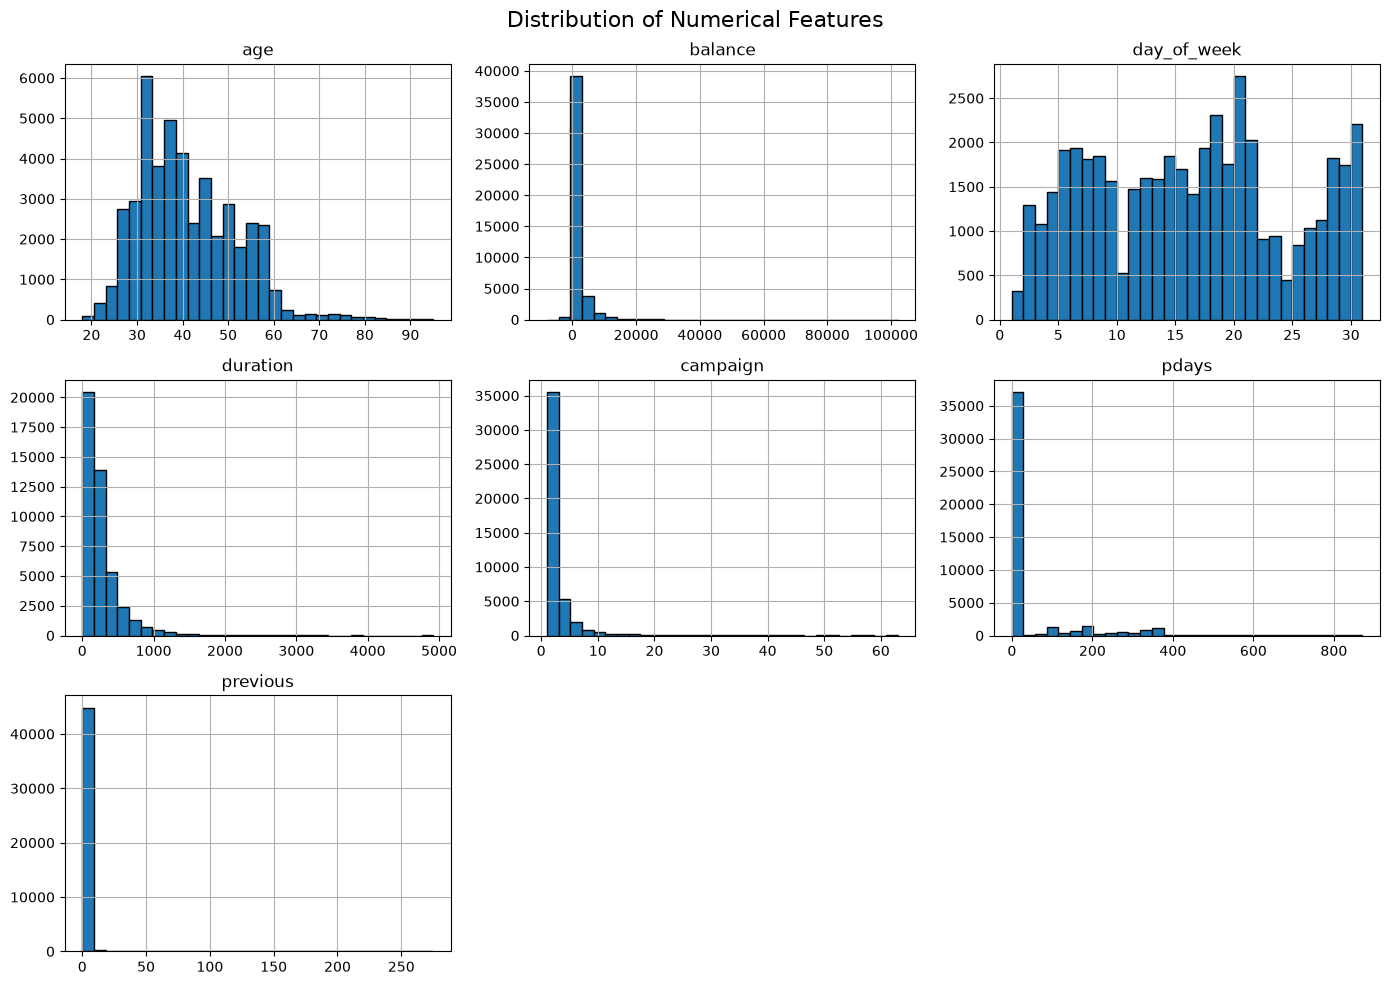

In [4]:
#numerical features
numerical_features = X.select_dtypes(include=np.number).columns.tolist()

X[numerical_features].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

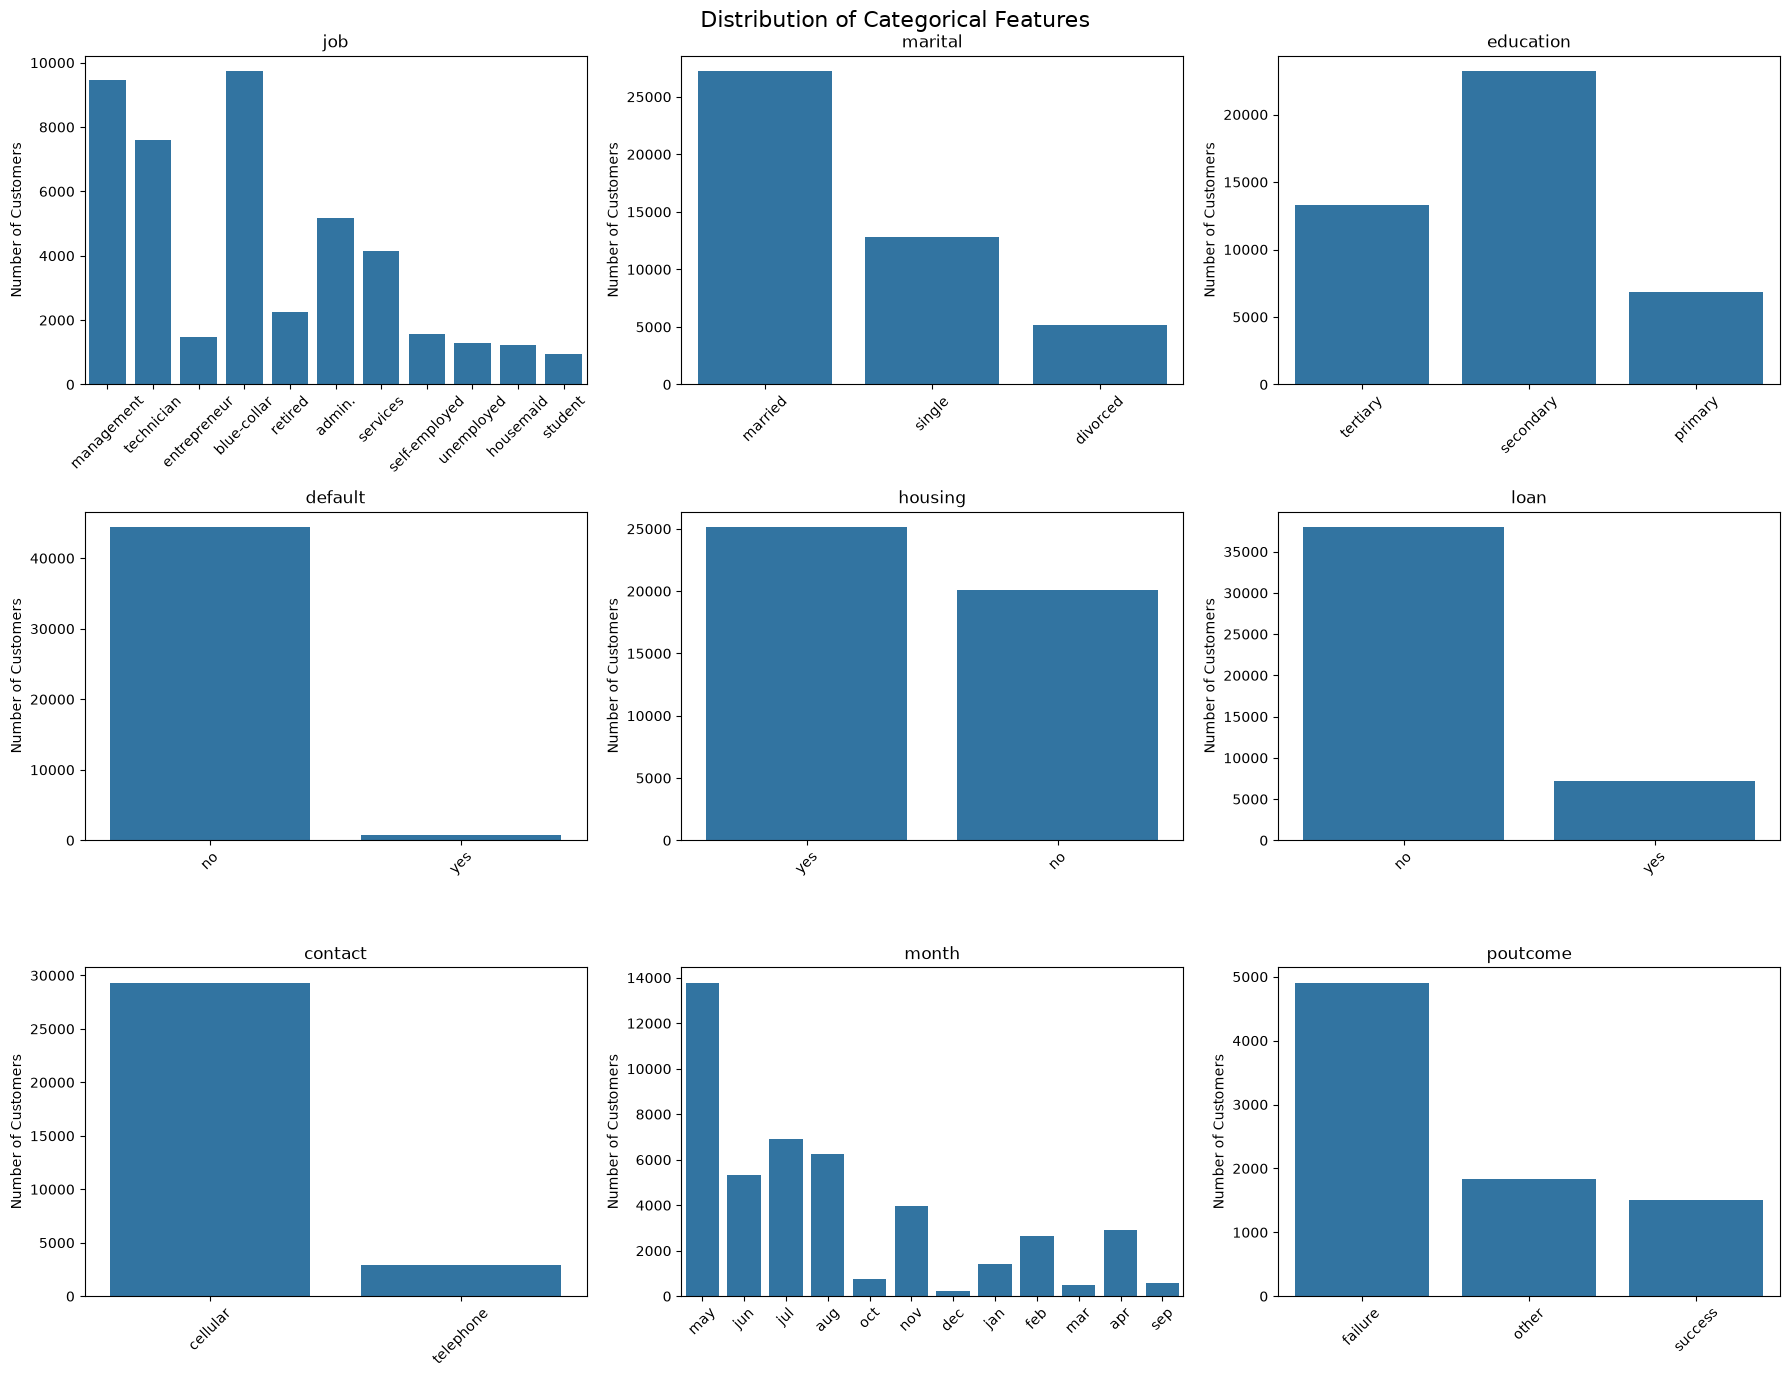

In [5]:
#categorical features
categorical_features = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

fig, axes = plt.subplots(
    nrows=(len(categorical_features) + 2) // 3,
    ncols=3,
    figsize=(18, 14)
)

axes = axes.flatten()

for ax, feature in zip(axes, categorical_features):
    sns.countplot(
        data=X,
        x=feature,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("Number of Customers")
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(categorical_features):]:
    ax.remove()

plt.suptitle("Distribution of Categorical Features", fontsize=16)
plt.tight_layout()
plt.show()

<Axes: >

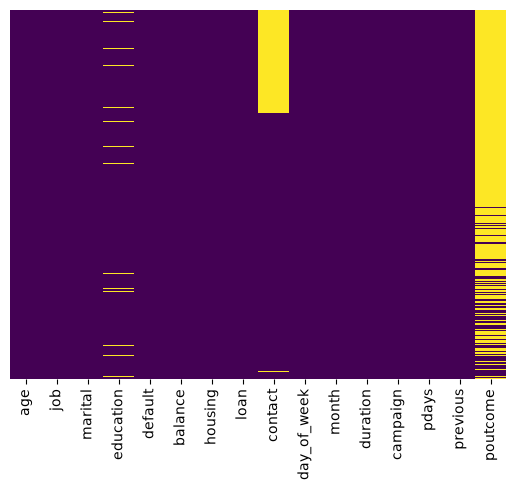

In [6]:
sns.heatmap(X.isnull(), yticklabels=False, cbar=False, cmap='viridis')

## Important Considerations

- Target value is not distributed equally -> consider within model training

- day of week seems to be day of month -> wrong metadata description

- duration isn't known before actual call -> drop in training

Noticiable things:
balance mostly 0 but some big outliers, same for campaign and pdays, contact mostly cellular, May most profitible, mostly nothing in default 

## Prepare Dataset

- 3 classes containing None -> all have unknown class so replace
- duration is not known before so drop (mentioned on database website)

In [7]:
X = X.drop(columns=["duration"])
X['education'] = X['education'].fillna('unknown')
X['contact'] = X['contact'].fillna('unknown')
X['poutcome'] = X['poutcome'].fillna('unknown')

y = bank_marketing.data.targets.squeeze()
y = y.map({"no": 0, "yes": 1})


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

In [8]:
numerical_features = [
    'age',
    'balance',
    'day_of_week',
    'campaign',
    'pdays',
    'previous'
]

categorical_features = [
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan',
    'contact',
    'month',
    'poutcome'
]
# numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

## Training:

Training well known Classifier model:
- Logistic Regression

Evaluating with following Metrics:
- Accuracy

- Precision

- Recall

- F1 Score

- ROC-AUC

Here, we have to consider both Recall and Precision. We want to cover as many potential customers as possible. But we don't reject precision / accuracy because reaching out to all customers would lead to 100 % recall but poor efficiency and potential high cost. F1 Score help us to determine the overall performance in regards to Precision and Recall. The ROC-curve shows us if our model is actually learning some decision boundary.


In [9]:
base_model = LogisticRegression(max_iter=2000)

X_train_processed= preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

base_model.fit(X_train_processed, y_train)

y_pred = base_model.predict(X_test_processed)

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.90      0.99      0.94     11977
           1       0.68      0.18      0.29      1587

    accuracy                           0.89     13564
   macro avg       0.79      0.59      0.62     13564
weighted avg       0.88      0.89      0.87     13564



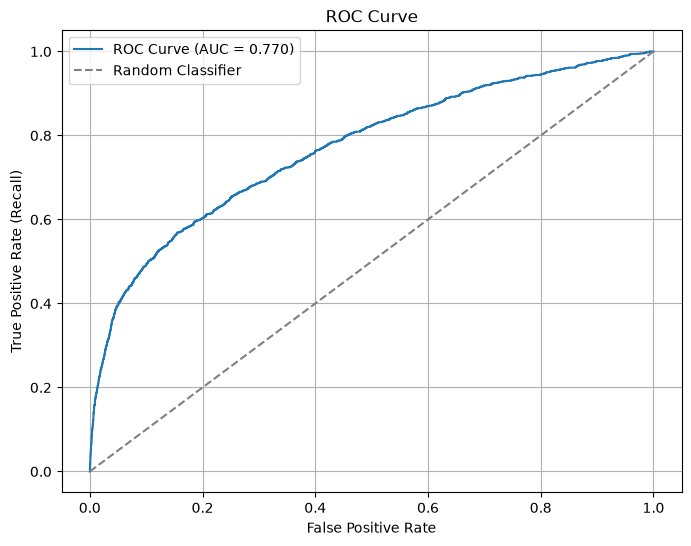

0.7698192697524278

In [10]:
y_prob = base_model.predict_proba(X_test_processed)[:, 1]

plot_roc_curve(y_test, y_prob)

### First Evaluation
Model is reasonable as seen in ROC Curve. But a basic model returning always False would achieve almost the same precision. However, goal is to optimize Recall aswell to cover as many possible customers.


Balanced class weights first

Also split additional validation set for threshold tuning later

In [11]:
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

X_train_scaled = preprocessor.fit_transform(X_train_new)
X_val_scaled = preprocessor.transform(X_val)
X_test_scaled = preprocessor.transform(X_test)

model = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

model.fit(X_train_scaled, y_train_new)
y_val_pred = model.predict(X_val_scaled)

print(classification_report(y_val, y_val_pred))



              precision    recall  f1-score   support

           0       0.94      0.77      0.85      5590
           1       0.27      0.63      0.37       740

    accuracy                           0.75      6330
   macro avg       0.60      0.70      0.61      6330
weighted avg       0.86      0.75      0.79      6330



### Balanced Weights evaluation
Model takes a big hit in precision (yes), but Recall is alot better

-> Precision - Recall Tradeoff

Try different thresholds

-> Compare F1 Scores and actual amount of contacts

In [12]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

y_val_prob = model.predict_proba(X_val_scaled)[:, 1]

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred, pos_label=1)
    recall = recall_score(y_val, y_val_pred, pos_label=1)
    f1 = f1_score(y_val, y_val_pred, pos_label=1)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred, labels=[0, 1]
    ).ravel()

    results.append({
        'Threshold': threshold,
        'True Positives': tp,
        'False Positives': fp,
        'False Negatives': fn,
        'True Negatives': tn,
        'Contact amount': tp + fp,
        'Contactquote %': (tp + fp) / len(y_val) * 100,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))


 Threshold  True Positives  False Positives  False Negatives  True Negatives  Contact amount  Contactquote %  Precision  Recall  F1-Score
       0.1             738             5512                2              78            6250          98.736      0.118   0.997     0.211
       0.2             711             4714               29             876            5425          85.703      0.131   0.961     0.231
       0.3             667             3806               73            1784            4473          70.664      0.149   0.901     0.256
       0.4             578             2536              162            3054            3114          49.194      0.186   0.781     0.300
       0.5             465             1277              275            4313            1742          27.520      0.267   0.628     0.375
       0.6             352              558              388            5032             910          14.376      0.387   0.476     0.427
       0.7             280        

## Evaluation of Thresholds:

Since we don't know the cost of contact we choose the threshold considering both the F1 Score and Contactquote: 0.6. 0.7 has a slightly better F1 Score but Contactquote suffers too much.

However, if the cost of contact is really low we would opt for a lower threshold e.g. 0.3 and if it was high: 0.8.

              precision    recall  f1-score   support

          no       0.93      0.90      0.92     11977
         yes       0.40      0.48      0.44      1587

    accuracy                           0.85     13564
   macro avg       0.66      0.69      0.68     13564
weighted avg       0.87      0.85      0.86     13564

[[10802  1175]
 [  818   769]]


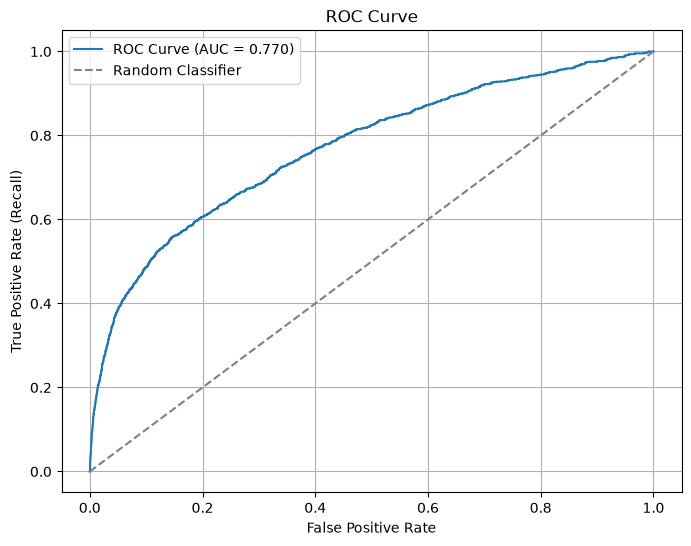

0.7700961604680343

In [13]:
y_test_prob = model.predict_proba(X_test_scaled)[:, 1]

best_threshold = 0.6

y_test_pred = (y_test_prob >= best_threshold).astype(int)

print(classification_report(
    y_test,
    y_test_pred,
    target_names=['no', 'yes']
))

print(confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
))

plot_roc_curve(y_test, y_test_prob)

## Evaluation

With the selected threshold the model correctly identifies approximately 50% of the subscriber while selecting 1,944 out of 13564 customers for contact. We have a decent accuracy and choose the threshold with the best F1 Score and customerquote in combination.

Again, we don't know the cost of contact, so we choose "the best of both worlds", but if it was known, choosing a different threshold might be more effective.

In [14]:
feature_names = preprocessor.get_feature_names_out()

feature_names = [name.replace("cat__", "").replace("num__", "") for name in feature_names]

coefficients = model.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Strength"] = feature_importance["Coefficient"].abs()

feature_importance = feature_importance.sort_values("Strength", ascending=False).reset_index(drop=True)

feature_importance.index += 1
feature_importance.index.name = "Rank"

display(
    feature_importance[["Feature", "Coefficient"]]
    .round(3)
    .style
    .format({"Coefficient": "{:+.3f}"})
    .background_gradient(subset=["Coefficient"], cmap="RdYlGn")
)

,Feature,Coefficient
Rank,,
1,poutcome_success,+1.632
2,month_mar,+1.220
3,month_jan,-1.026
4,month_dec,+0.975
5,month_oct,+0.959
6,month_nov,-0.811
7,month_sep,+0.771
8,month_aug,-0.765
9,contact_unknown,-0.712


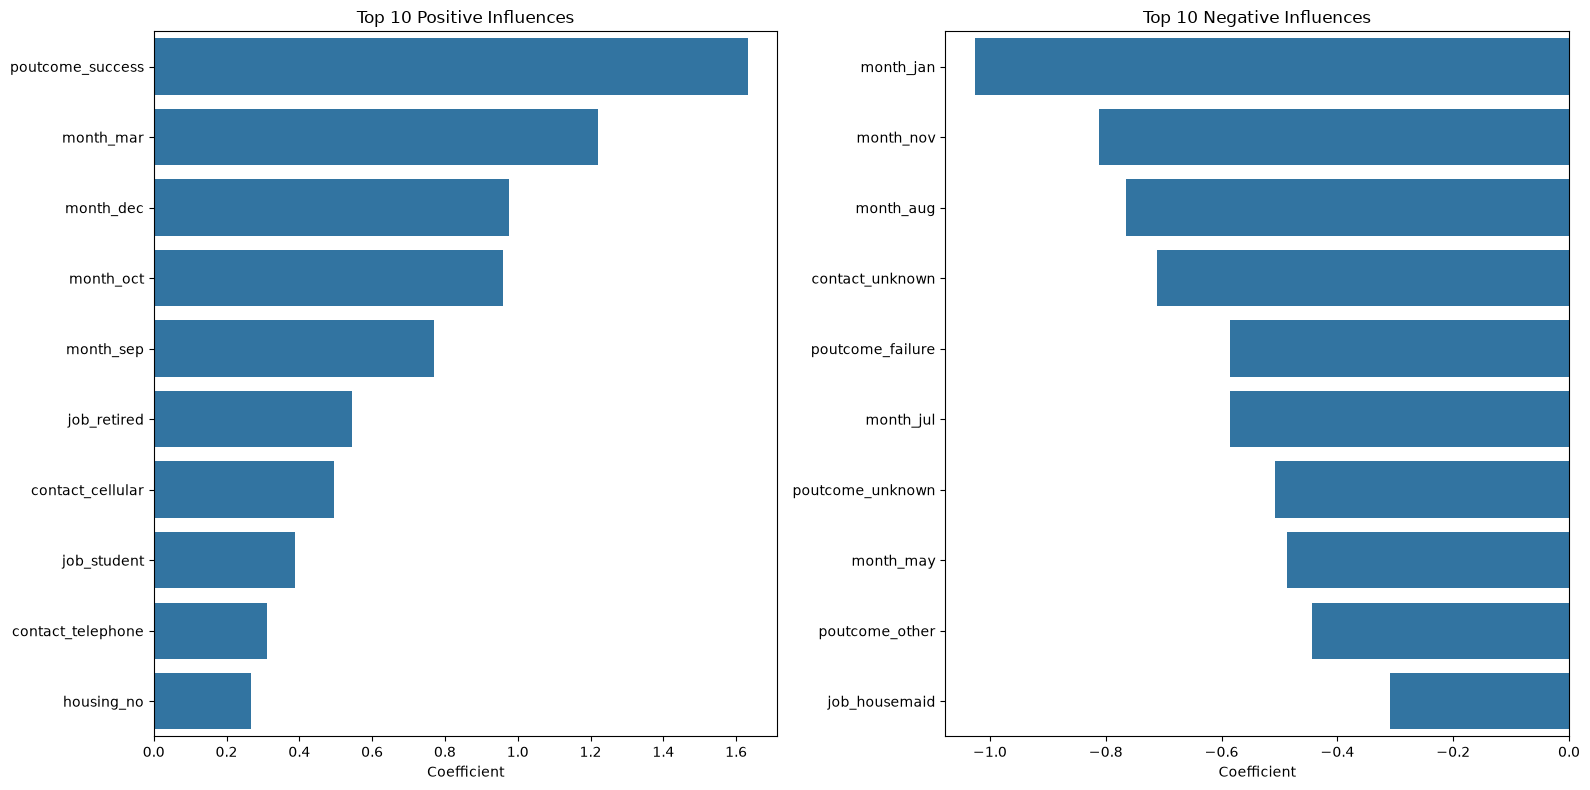

In [15]:
top_positive = feature_importance.nlargest(10, "Coefficient")
top_negative = feature_importance.nsmallest(10, "Coefficient")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# positive impacts
sns.barplot(
    data=top_positive.sort_values("Coefficient", ascending=False),
    x="Coefficient",
    y="Feature",
    ax=axes[0]
)
axes[0].set_title("Top 10 Positive Influences")
axes[0].set_xlabel("Coefficient")
axes[0].set_ylabel("")

# negative impacts
sns.barplot(
    data=top_negative.sort_values("Coefficient"),
    x="Coefficient",
    y="Feature",
    ax=axes[1]
)
axes[1].set_title("Top 10 Negative Influences")
axes[1].set_xlabel("Coefficient")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

Here we see the top 10 biggest positive influences and negative influences. It seems that especially the chosen month is an important factor in both positive and negative way. Another big postive influence is whether the last campaign was a success and therefore a negative influence if it wasn't. The coefficients of all features can be seen in the table one cell above.

In [16]:
# example usage for single customer:
new_customer = pd.DataFrame([{
    'age': 35,
    'job': 'management',
    'marital': 'married',
    'education': 'tertiary',
    'default': 'no',
    'balance': 1500,
    'housing': 'yes',
    'loan': 'no',
    'contact': 'cellular',
    'day_of_week': 15,
    'month': 'mar',
    'campaign': 1,
    'pdays': -1,
    'previous': 0,
    'poutcome': 'unknown'
}])

new_customer_processed = preprocessor.transform(new_customer)


probability = model.predict_proba(new_customer_processed)[0][1]
prediction = int(probability >= best_threshold) # best_threshold was 0.6



print("Probability of subscription:", round(probability * 100, 2), "%")

if prediction == 1:
    print("Prediction: YES")
else:
    print("Prediction: NO")

Probability of subscription: 83.0 %
Prediction: YES


Graphs for report:

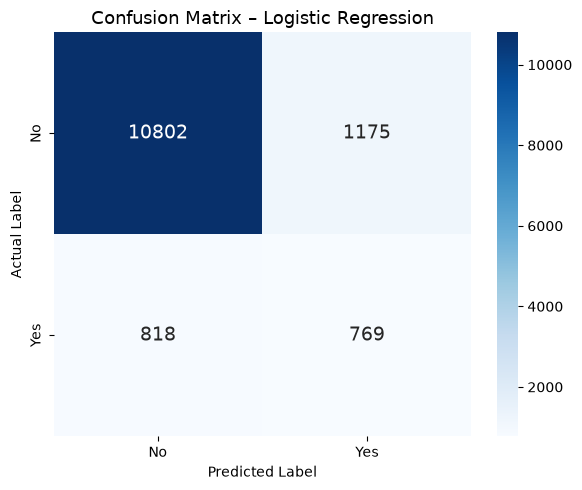

In [ ]:
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"],
    annot_kws={"size": 14}
)

plt.title("Confusion Matrix – Logistic Regression", fontsize=13)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.show()

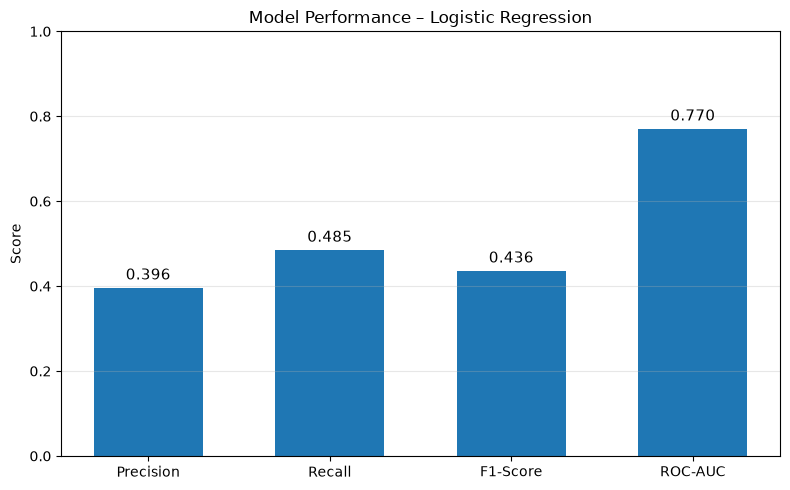

In [18]:
precision = precision_score(y_test, y_test_pred, pos_label=1)
recall = recall_score(y_test, y_test_pred, pos_label=1)
f1 = f1_score(y_test, y_test_pred, pos_label=1)
roc_auc = roc_auc_score(y_test, y_test_prob)

metrics = {
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "ROC-AUC": roc_auc
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics.keys(),
    metrics.values(),
    width=0.6
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Model Performance – Logistic Regression")

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        fontsize=11
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()